# Notebook 01: Modelado con K-Means — Fase 3: EDA

**Responsable:** Gloria Chushig  
**Objetivo de esta fase:** describir las 16 variables numéricas acordadas, revisar valores extremos, estudiar la estructura de correlación y entender qué resumen ofrecen las dos primeras componentes principales. Las etiquetas `Burnout_Level` y `Dropout_Risk` no se usan en ningún cálculo de esta fase ni en el ajuste espacial.

Este notebook continúa en fases posteriores con la selección de K y el entrenamiento final. Aquí se prepara una lectura reproducible de los datos para entender sus propiedades antes del agrupamiento.

## 1. Carga controlada de los datos

**Propósito y fundamento:** se cargan las variables aprobadas en el mismo orden del contrato técnico. La matriz escalada y el PCA provienen de `00_foundation.py`, lo que mantiene una base común entre los integrantes. Las columnas categóricas y las etiquetas de clase quedan fuera del análisis espacial.

In [1]:
# Librerías para cargar datos, transformar matrices y crear las figuras del análisis.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Se fija la semilla que se comparte con las demás fases para reproducir el modelo.
RANDOM_STATE = 42
ROOT = Path.cwd()
DATA = ROOT / "data"
# Se toma el orden oficial de variables del artefacto fundacional; las etiquetas no forman parte de FEATURES.
FEATURES = json.loads((DATA / "feature_names.json").read_text(encoding="utf-8"))
df = pd.read_csv(DATA / "student_burnout_dropout_dataset_2_link 1.csv")
# X_raw conserva solo las 16 variables numéricas y su escala original para los análisis descriptivos.
X_raw = df.loc[:, FEATURES].copy()
# Esta matriz ya fue imputada y estandarizada por 00_foundation.py; se usa en codo y Silhouette.
X_scaled = pd.read_csv(DATA / "X_scaled.csv").loc[:, FEATURES]
pca_variance = pd.read_csv(DATA / "pca_varianza.csv")
# Se carga el PCA fundacional para inspeccionar varianza y loadings, sin volver a ajustarlo.
pca = joblib.load(ROOT / "models" / "pca.joblib")

print(f"Dataset: {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"Variables de análisis: {len(FEATURES)}")
print("Etiquetas excluidas del análisis espacial: Burnout_Level, Dropout_Risk")
# El resumen permite revisar rangos, medias y dispersión antes de comparar variables.
display(X_raw.describe().T.round(2))

Dataset: 800 filas × 25 columnas
Variables de análisis: 16
Etiquetas excluidas del análisis espacial: Burnout_Level, Dropout_Risk


,count,mean,std,min,25%,50%,75%,max
Age,800.0,20.88,2.60,17.00,19.00,21.00,23.00,25.0
Year_of_Study,800.0,2.28,1.11,1.00,1.00,2.00,3.00,4.0
Attendance_Percent,749.0,76.88,14.26,30.00,66.20,77.40,88.60,100.0
Study_Hours_Per_Day,765.0,3.16,1.56,0.00,2.10,3.10,4.20,8.1
Previous_GPA,765.0,6.86,1.40,2.42,5.88,6.86,7.80,10.0
Backlogs,785.0,0.82,0.94,0.00,0.00,1.00,1.00,6.0
Sleep_Hours,765.0,6.20,1.50,2.00,5.20,6.30,7.20,10.0
Screen_Time_Hours,764.0,5.43,2.20,0.50,3.98,5.45,6.93,12.6
Exercise_Freq_Per_Week,800.0,2.01,1.48,0.00,1.00,2.00,3.00,7.0
Social_Activity_Score,760.0,4.99,1.96,0.00,3.60,5.00,6.40,10.0


**Interpretación y Argumento para Defensa:** la tabla describe los rangos y la dispersión de 800 estudiantes; permite ver que las variables tienen unidades y escalas distintas antes del agrupamiento. **Decisión técnica:** se mantienen las 16 variables del contrato, con imputación mediana y estandarización en el pipeline; las etiquetas objetivo permanecen excluidas. **Defensa:** si preguntan por qué `StandardScaler`, responde que K-Means usa distancias euclidianas y centrar/escalar cada variable evita que su unidad o rango domine la distancia. MinMaxScaler también reescala, pero depende de los extremos observados y no garantiza varianza comparable.

## 2. Correlaciones entre variables

**Propósito y fundamento:** el coeficiente de Pearson resume la asociación lineal entre pares de variables. Valores cercanos a 1 o −1 indican asociación lineal positiva o negativa; valores cercanos a 0 indican poca asociación lineal. La correlación no demuestra causalidad y las variables correlacionadas pueden dar peso redundante a una dimensión en las distancias.

Pares con |correlación de Pearson| ≥ 0.50:


,variable_1,variable_2,correlation


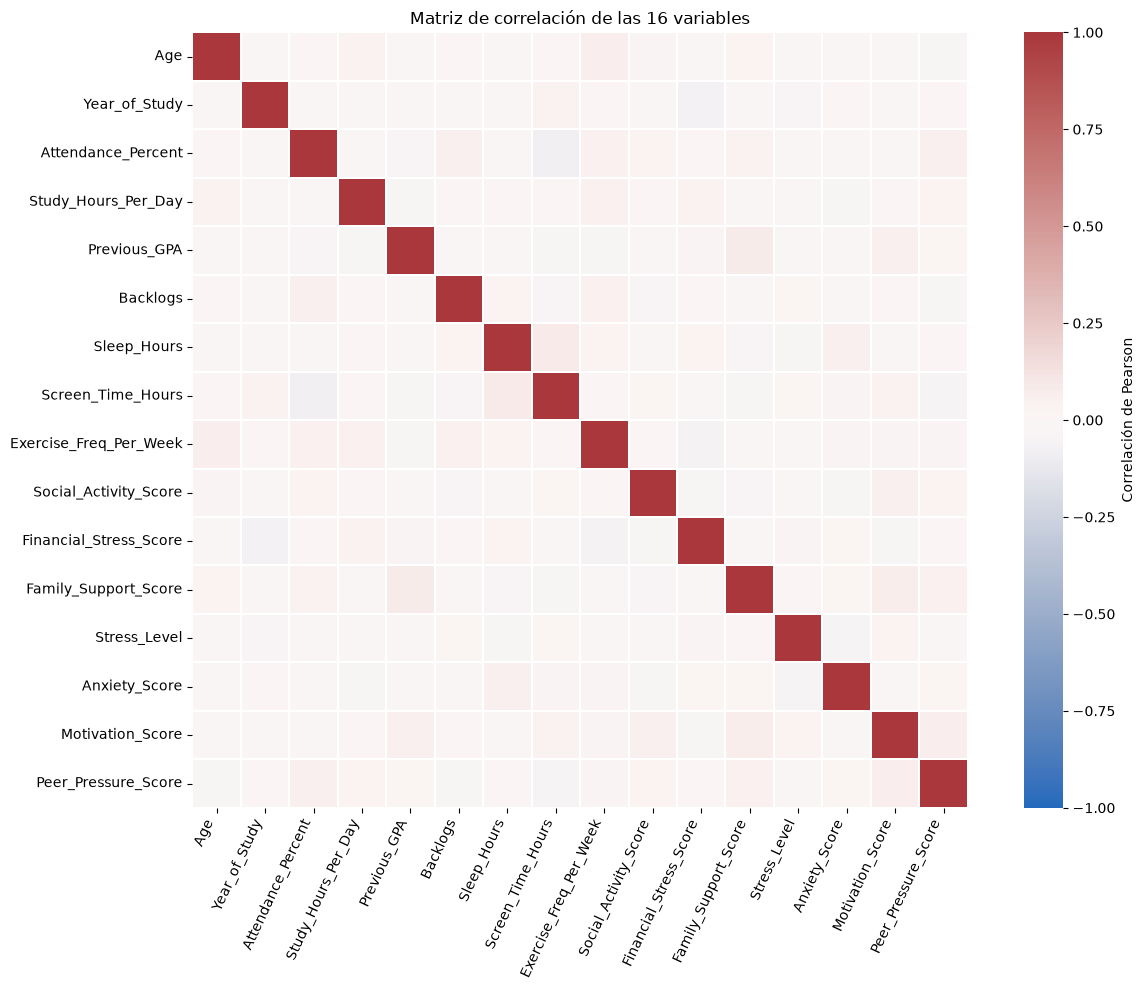

In [2]:
# Pearson mide asociación lineal entre las variables originales; no implica causalidad.
corr = X_raw.corr(numeric_only=True)
# Se conserva solo el triángulo superior para no contar dos veces cada par ni incluir la diagonal.
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("correlation")
# El umbral |r| >= 0.50 se usa como señal exploratoria de asociaciones relativamente fuertes.
strong_pairs = pairs.loc[pairs.abs() >= 0.50].sort_values(key=np.abs, ascending=False)
print("Pares con |correlación de Pearson| ≥ 0.50:")
display(strong_pairs.rename_axis(["variable_1", "variable_2"]).reset_index().round(3))

# El mapa usa una escala simétrica de -1 a 1 para comparar dirección e intensidad.
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.25, cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación de las 16 variables")
plt.xticks(rotation=65, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** no hay pares con correlación de Pearson de magnitud |r| ≥ 0.50, por lo que el umbral no detecta asociaciones lineales fuertes ni redundancias dominantes. Eso no implica independencia ni descarta asociaciones no lineales. **Decisión técnica:** se conservan las 16 variables fijadas por el contrato; la correlación se usa como diagnóstico descriptivo. **Defensa:** Pearson mide asociación lineal y no demuestra que una variable cause la otra.

## 3. Detección de valores extremos y visualización

**Propósito y fundamento:** se marcan valores fuera de los límites de Tukey, definidos como Q1 − 1.5×IQR y Q3 + 1.5×IQR, calculados variable por variable en escala original. Esta regla es exploratoria: señala observaciones alejadas del rango central, pero no prueba que sean errores. Se visualizarán distribuciones y boxplots estandarizados para comparar variables con distintas unidades.

Resumen univariado de outliers por regla 1.5×IQR:


,n_outliers,pct_outliers,lower_fence,upper_fence
Backlogs,41,5.12,-1.50,2.50
Exercise_Freq_Per_Week,9,1.12,-2.00,6.00
Sleep_Hours,6,0.75,2.20,10.20
Study_Hours_Per_Day,6,0.75,-1.05,7.35
Peer_Pressure_Score,3,0.38,-0.55,9.45
Family_Support_Score,2,0.25,0.65,12.25
Screen_Time_Hours,2,0.25,-0.45,11.35
Previous_GPA,2,0.25,3.00,10.68
Attendance_Percent,1,0.12,32.60,122.20
Stress_Level,1,0.12,0.15,10.95


Celdas-variable marcadas como extremas: 73 de 12800 (0.57%).


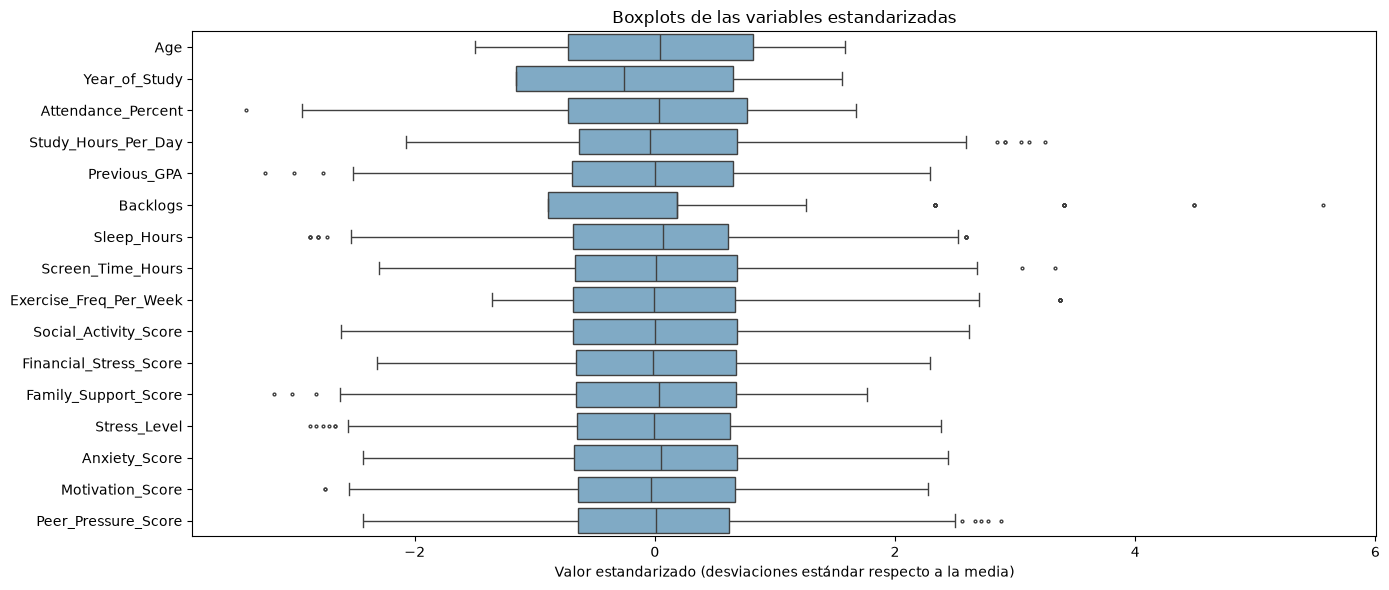

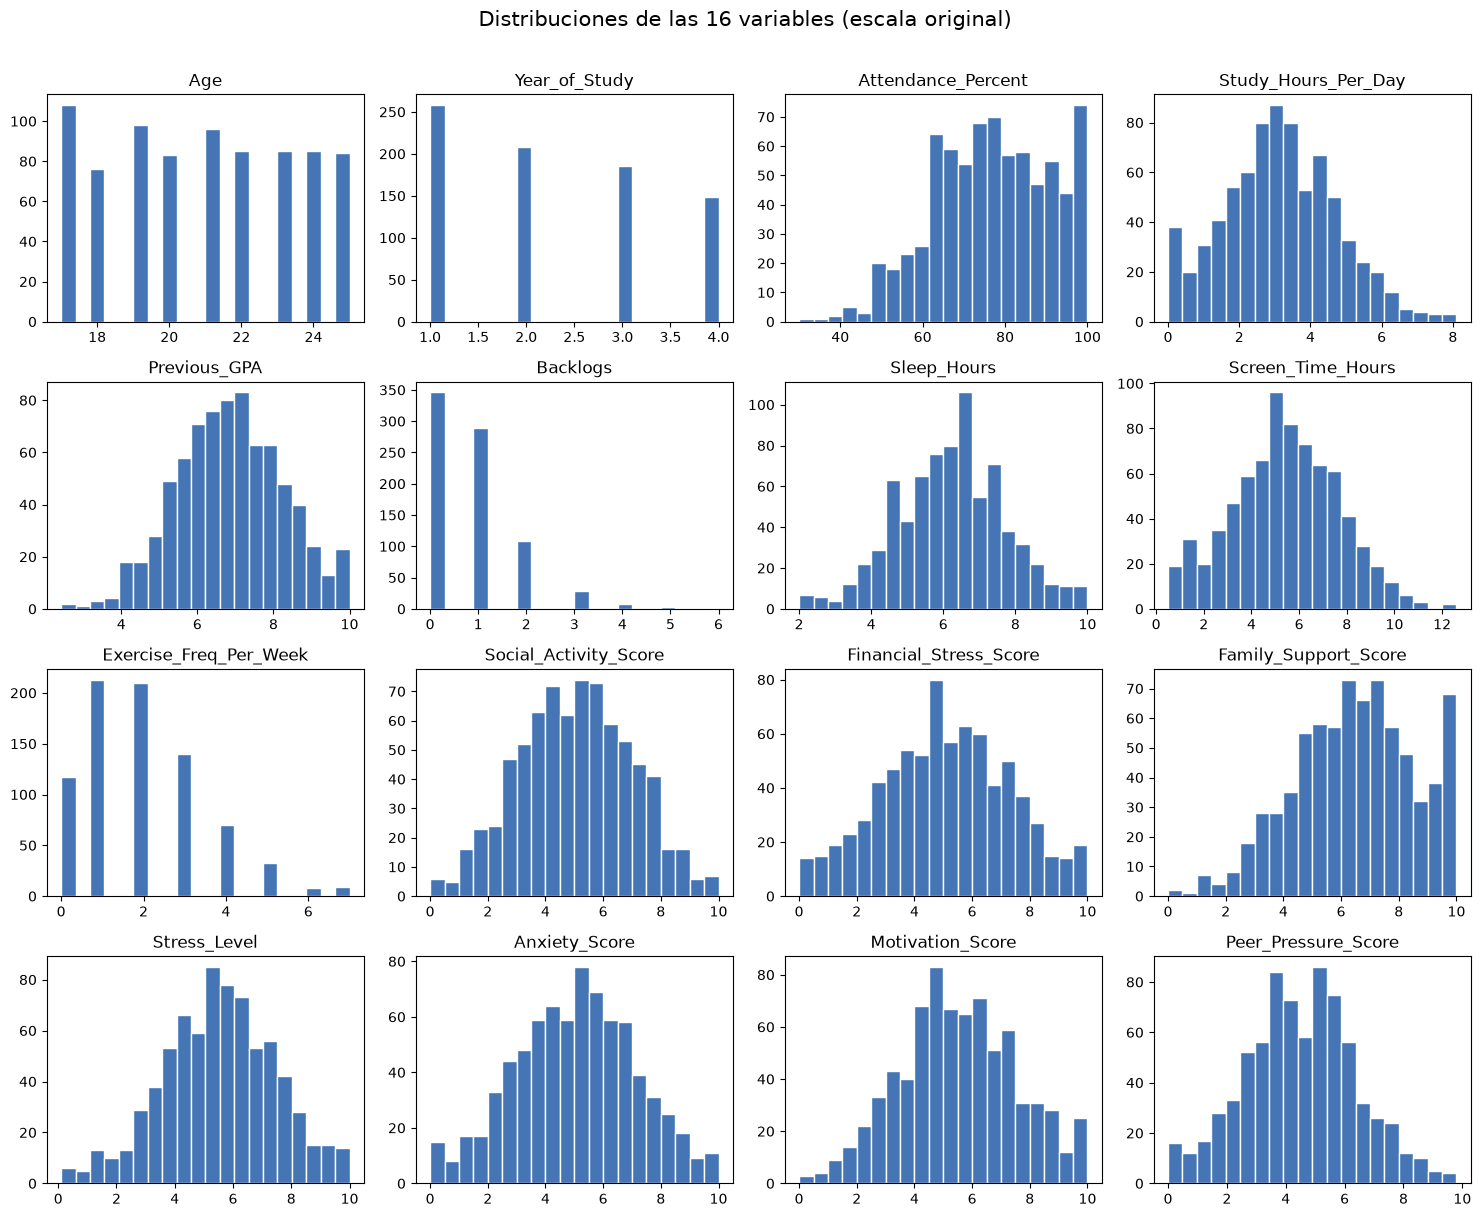

In [3]:
# Se aplican los límites de Tukey por variable: Q1/Q3 y 1.5 veces el rango intercuartílico.
q1 = X_raw.quantile(0.25)
q3 = X_raw.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
# La máscara marca celdas fuera de los límites; no elimina observaciones del dataset.
outlier_mask = X_raw.lt(lower) | X_raw.gt(upper)
# Se cuentan celdas extremas y se registran límites para identificar variables que requieren revisión.
outlier_summary = pd.DataFrame({
    "n_outliers": outlier_mask.sum(),
    "pct_outliers": (100 * outlier_mask.mean()),
    "lower_fence": lower,
    "upper_fence": upper,
}).sort_values("n_outliers", ascending=False)
print("Resumen univariado de outliers por regla 1.5×IQR:")
display(outlier_summary.round(2))
print(f"Celdas-variable marcadas como extremas: {int(outlier_mask.to_numpy().sum())} de {X_raw.size} ({outlier_mask.to_numpy().mean():.2%}).")

# Los boxplots usan la matriz estandarizada para que las 16 variables sean comparables en una escala común.
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=X_scaled, orient="h", color="#74add1", fliersize=2, ax=ax)
ax.set_title("Boxplots de las variables estandarizadas")
ax.set_xlabel("Valor estandarizado (desviaciones estándar respecto a la media)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Los histogramas mantienen la escala original y muestran la forma de cada distribución por separado.
axes = X_raw.hist(figsize=(15, 12), bins=20, grid=False, color="#4575b4", edgecolor="white")
plt.suptitle("Distribuciones de las 16 variables (escala original)", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** se marcaron 73 celdas-variable extremas de 12.800 (0,57 %); `Backlogs` concentra 41, seguido por `Exercise_Freq_Per_Week` con 9. Como K-Means usa medias y distancias a centroides, esos extremos pueden mover los centroides. **Decisión técnica:** no se eliminan observaciones solo por superar 1.5×IQR; se conservan y se consideran al interpretar perfiles. **Defensa:** IQR es una alerta exploratoria, no evidencia de error; primero se necesitaría revisar el registro y su contexto.

## 4. Varianza explicada y lectura de PCA

**Propósito y fundamento:** PCA transforma variables correlacionadas en componentes ortogonales ordenadas por varianza capturada. La varianza explicada indica cuánta variabilidad resume cada componente y la acumulada cuánto resumen varias componentes juntas. Se reportan todas las componentes; PCA se reserva para exploración visual y no sustituye el espacio 16D del futuro K-Means.

Varianza explicada y acumulada por componente:


,component,explained_variance,cumulative
0,PC1,0.0762,0.0762
1,PC2,0.0741,0.1504
2,PC3,0.0720,0.2223
3,PC4,0.0703,0.2926
4,PC5,0.0685,0.3611
5,PC6,0.0662,0.4272
6,PC7,0.0659,0.4931
7,PC8,0.0621,0.5552
8,PC9,0.0619,0.6171
9,PC10,0.0587,0.6759


PC1 + PC2 explican 15.04% de la varianza total.


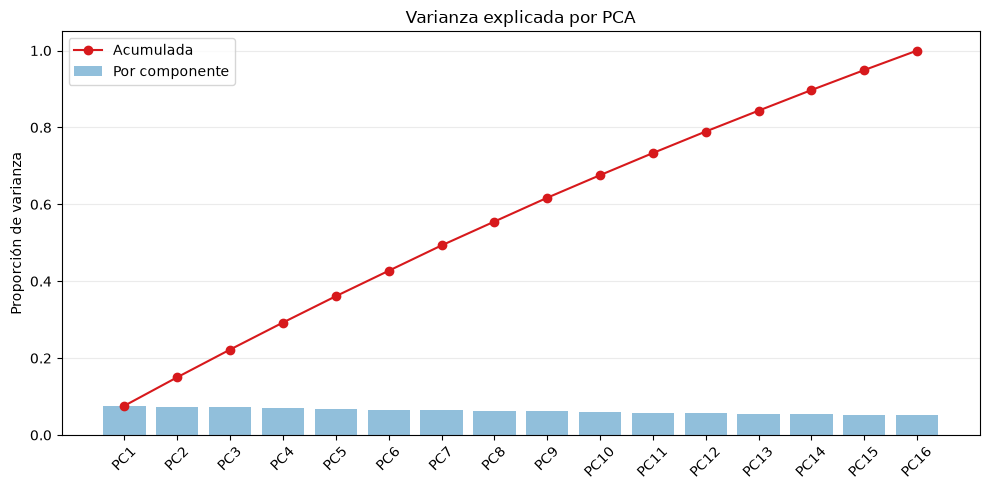

Variables con mayor |loading| en PC1:


,abs_loading,loading
Family_Support_Score,0.482,0.482
Screen_Time_Hours,0.405,-0.405
Previous_GPA,0.385,0.385
Peer_Pressure_Score,0.340,0.340
Sleep_Hours,0.339,-0.339
Motivation_Score,0.304,0.304


Variables con mayor |loading| en PC2:


,abs_loading,loading
Exercise_Freq_Per_Week,0.562,0.562
Attendance_Percent,0.357,0.357
Age,0.351,0.351
Financial_Stress_Score,0.287,-0.287
Previous_GPA,0.279,-0.279
Study_Hours_Per_Day,0.275,0.275


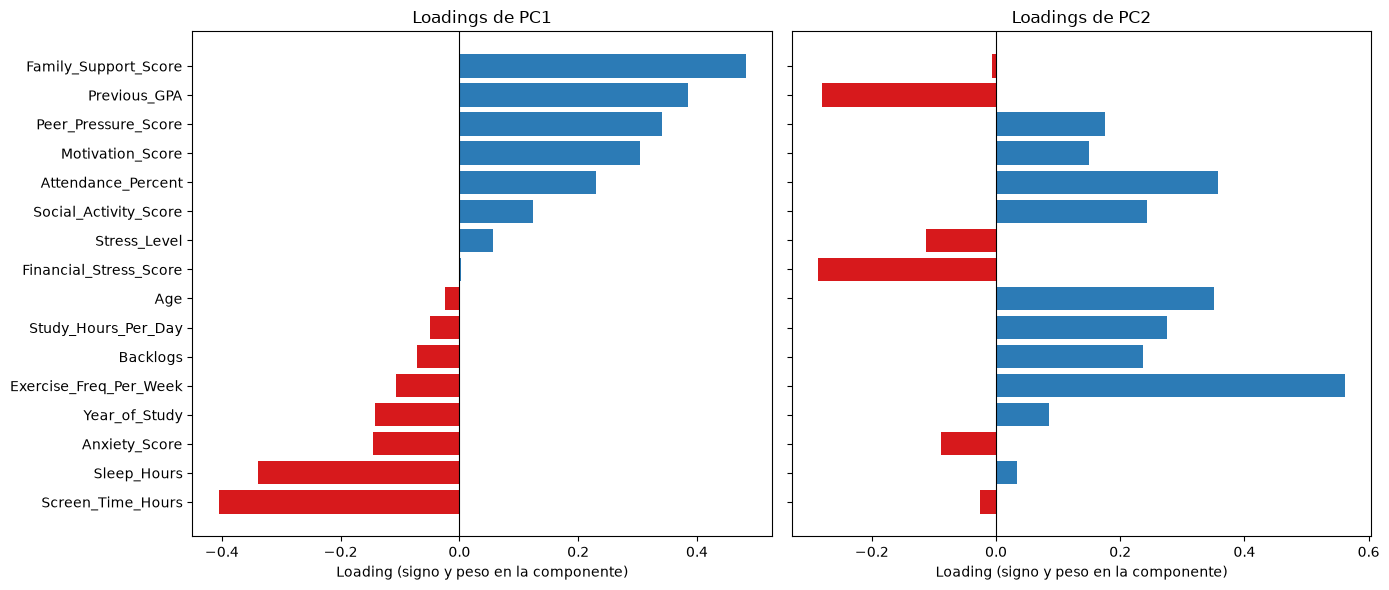

In [4]:
# La tabla reporta la contribución de cada componente y la proporción acumulada.
print("Varianza explicada y acumulada por componente:")
display(pca_variance.round(4))
print(f"PC1 + PC2 explican {pca_variance.loc[:1, 'explained_variance'].sum():.2%} de la varianza total.")

# Barras: varianza por componente; línea: varianza acumulada al incorporar componentes.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pca_variance["component"], pca_variance["explained_variance"], color="#91bfdb", label="Por componente")
ax.plot(pca_variance["component"], pca_variance["cumulative"], color="#d7191c", marker="o", label="Acumulada")
ax.set_ylabel("Proporción de varianza")
ax.set_title("Varianza explicada por PCA")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

# Las filas de components_ son ejes PCA; la transposición deja una fila por variable.
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
# Se ordenan los pesos por magnitud para identificar las variables que más definen cada eje.
for component in loadings.columns:
    print(f"Variables con mayor |loading| en {component}:")
    display(loadings[component].abs().sort_values(ascending=False).head(6).rename("abs_loading").to_frame().join(loadings[component].rename("loading")).round(3))

# Los gráficos de loadings conservan el signo, aunque la orientación global de cada componente es arbitraria.
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, component in zip(axes, ["PC1", "PC2"]):
    vals = loadings[component].sort_values()
    ax.barh(vals.index, vals.values, color=np.where(vals.values >= 0, "#2c7bb6", "#d7191c"))
    ax.axvline(0, color="black", linewidth=.8)
    ax.set_title(f"Loadings de {component}")
    ax.set_xlabel("Loading (signo y peso en la componente)")
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** PC1 explica 7,62 % y PC2 7,41 %; juntas retienen 15,04 % de la varianza, así que el mapa 2D solo muestra una fracción de la estructura. En PC1 pesan más `Family_Support_Score` (+0,482), `Screen_Time_Hours` (−0,405), `Previous_GPA` (+0,385), `Peer_Pressure_Score` (+0,340), `Sleep_Hours` (−0,339) y `Motivation_Score` (+0,304): un eje mixto de apoyo/rendimiento y hábitos. En PC2 destacan ejercicio (+0,562), asistencia (+0,357) y edad (+0,351), frente a estrés financiero (−0,287) y GPA (−0,279): un contraste aproximado entre actividad/participación y presión financiera/rendimiento. **Decisión técnica:** PCA se reserva para visualizar; K-Means se ajusta en las 16 dimensiones. **Defensa:** los loadings muestran la contribución relativa de variables; el signo global de un componente es arbitrario y estas etiquetas de negocio son interpretaciones, no causas ni índices validados.

## Cierre de la Fase 3

Este EDA deja documentados los rangos, correlaciones, extremos univariados, distribuciones, varianza explicada y loadings. Los límites 1.5×IQR y |r| ≥ 0.50 se usan como criterios descriptivos para llamar la atención, no como reglas automáticas de filtrado. La matriz de modelado conserva las 16 variables acordadas; en la siguiente fase se seleccionará K mediante codo y Silhouette sobre el espacio escalado completo.

## Fase 4 — Selección del número de clusters K

**Propósito y fundamento:** se comparan K=2,…,9 sobre las 16 variables de `X_scaled.csv`. La inercia es la suma de distancias cuadráticas de cada observación a su centroide y siempre disminuye al aumentar K; se busca el tramo donde esa mejora empieza a rendir menos (codo). Silhouette compara cohesión dentro del cluster con separación del más cercano y toma valores entre −1 y 1; valores mayores indican mejor separación. Se fijan `random_state=42` y `n_init=10` para reproducibilidad. La selección es una decisión conjunta: evidencia geométrica más perfiles suficientemente simples para comunicar.

Comparación de K sobre el espacio escalado de 16 dimensiones:


,K,inertia,silhouette,inertia_reduction_pct
0,2,12155.05,0.0489,NaN
1,3,11700.07,0.0457,3.74
2,4,11290.70,0.0475,3.50
3,5,10982.51,0.0480,2.73
4,6,10722.26,0.0486,2.37
5,7,10502.56,0.0475,2.05
6,8,10300.58,0.0495,1.92
7,9,10110.36,0.0501,1.85


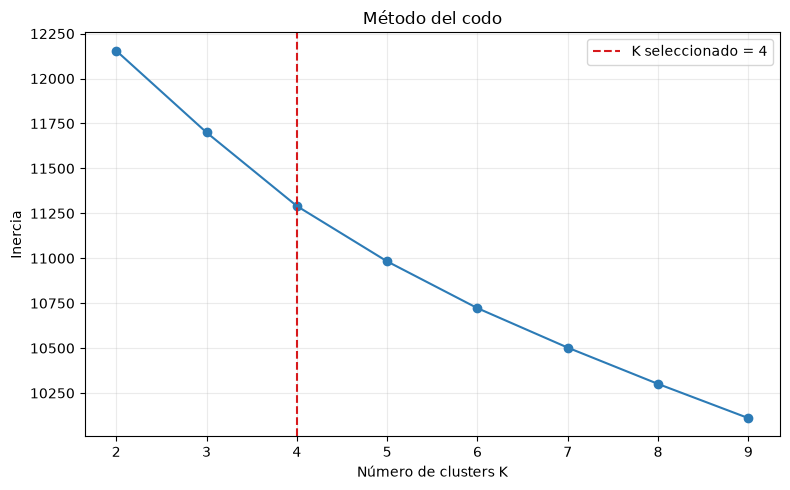

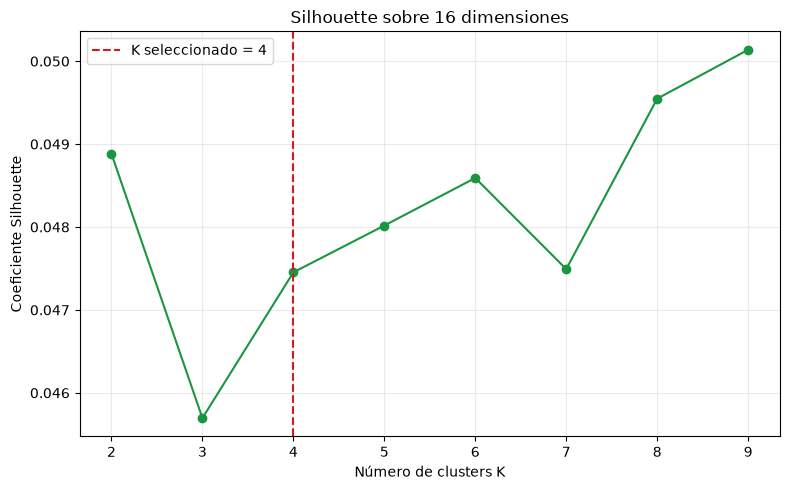

Decisión de esta fase: K=4; Silhouette=0.0475; inercia=11290.70.
Máximo Silhouette evaluado: K=9, 0.0501.


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Se evalúa el rango acordado K=2,...,9 con idénticos datos, semilla e inicializaciones.
candidate_ks = range(2, 10)
selection_rows = []
# Cada ajuste produce etiquetas, inercia y Silhouette en el espacio completo de 16 dimensiones.
for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    selection_rows.append({
        "K": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })
selection = pd.DataFrame(selection_rows)
# La reducción porcentual ayuda a observar cuánto menor es la mejora marginal al aumentar K.
selection["inertia_reduction_pct"] = -100 * selection["inertia"].diff() / selection["inertia"].shift(1)
print("Comparación de K sobre el espacio escalado de 16 dimensiones:")
display(selection.round({"inertia": 2, "silhouette": 4, "inertia_reduction_pct": 2}))

# La curva de inercia ayuda a localizar un codo aproximado; la inercia siempre baja al subir K.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["inertia"], marker="o", color="#2c7bb6")
ax.axvline(4, color="#d7191c", linestyle="--", label="K seleccionado = 4")
ax.set(title="Método del codo", xlabel="Número de clusters K", ylabel="Inercia")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Esta curva compara cohesión y separación para cada candidato K.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["silhouette"], marker="o", color="#1a9641")
ax.axvline(4, color="#d7191c", linestyle="--", label="K seleccionado = 4")
ax.set(title="Silhouette sobre 16 dimensiones", xlabel="Número de clusters K", ylabel="Coeficiente Silhouette")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Se registra K=4 como compromiso provisional según el codo aproximado y la interpretabilidad.
selected_k = 4
selected_row = selection.loc[selection["K"] == selected_k].iloc[0]
best_row = selection.loc[selection["silhouette"].idxmax()]
print(f"Decisión de esta fase: K={selected_k}; Silhouette={selected_row['silhouette']:.4f}; inercia={selected_row['inertia']:.2f}.")
print(f"Máximo Silhouette evaluado: K={int(best_row['K'])}, {best_row['silhouette']:.4f}.")

**Interpretación y Argumento para Defensa:** la inercia baja de 12.155 a 10.111 entre K=2 y K=9, pero cada incremento de K aporta una reducción porcentual menor; el cambio pasa de 3,50 % al pasar de K=3 a 4 a 2,73 % de K=4 a 5. Se toma **K=4 como codo aproximado**, porque desde allí las ganancias de inercia son más pequeñas y se evita dividir la población en demasiados perfiles. Silhouette es bajo en todos los candidatos (0,0457–0,0501): su máximo es K=9 (0,0501), mientras que K=4 alcanza 0,0475, solo 0,0026 menos. Por ello no existe evidencia de separación natural fuerte; K=4 es un compromiso provisional entre la curva del codo, una Silhouette cercana al máximo y perfiles más manejables para acciones institucionales. En la fase siguiente se debe revisar si esos cuatro perfiles son interpretables y accionables; si no lo son, la elección se reevalúa. **Defensa:** “No elegí K por maximizar una sola métrica: K=9 mejora Silhouette apenas 0,0026 y está en el límite del rango probado; elegí el codo aproximado K=4 para conservar una segmentación más simple, reconociendo que Silhouette bajo indica separación débil”.

### Decisión registrada

El valor candidato que pasa a la fase de entrenamiento final es **K=4** (`selected_k = 4`). Los resultados de este barrido no entrenan ni exportan todavía el pipeline definitivo; esa tarea corresponde a la Fase 5.

## Fase 5 — Entrenamiento final de K-Means

**Propósito y fundamento:** se entrena el candidato seleccionado, K=4, con la matriz cruda de las 16 variables. El Pipeline aplica imputación por mediana, estandarización y K-Means en ese orden; así cualquier registro pasa por las mismas transformaciones. K-Means minimiza la suma de distancias euclidianas cuadradas a los centroides. Se fija `random_state=42` y `n_init=10`, como en la comparación de K.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# El Pipeline asegura que entrenamiento e inferencia apliquen las transformaciones en el mismo orden.
pipeline_kmeans = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=10)),
])
# Se ajusta sobre las variables crudas; el Pipeline imputa, escala y luego entrena K-Means.
pipeline_kmeans.fit(X_raw)
# Las etiquetas se conservan en el mismo orden de las filas originales.
labels_kmeans = pipeline_kmeans.named_steps["kmeans"].labels_
X_model_space = pipeline_kmeans[:-1].transform(X_raw)
# Silhouette se calcula en las 16 dimensiones ya escaladas, no sobre la proyección PCA 2D.
silhouette_final = silhouette_score(X_model_space, labels_kmeans)
# Los tamaños permiten revisar si la solución genera grupos vacíos o muy pequeños.
cluster_sizes = pd.Series(labels_kmeans, name="cluster").value_counts().sort_index().rename("n_estudiantes").to_frame()

print(f"K entrenado: {selected_k}")
print(f"Inercia final: {pipeline_kmeans.named_steps['kmeans'].inertia_:.2f}")
print(f"Silhouette final en 16D: {silhouette_final:.4f}")
print("Tamaño de cada grupo:")
display(cluster_sizes)
print(f"Total asignado: {int(cluster_sizes['n_estudiantes'].sum())} de {len(X_raw)} registros")

K entrenado: 4
Inercia final: 11290.70
Silhouette final en 16D: 0.0475
Tamaño de cada grupo:


,n_estudiantes
cluster,
0,171
1,220
2,206
3,203


Total asignado: 800 de 800 registros


**Interpretación y Argumento para Defensa:** el modelo se ajustó en las 16 dimensiones; obtuvo inercia 11.290,70 y Silhouette 0,0475, coherente con el barrido para K=4. El valor bajo refleja separación débil. Los tamaños son 171, 220, 206 y 203 estudiantes, sin un grupo diminuto. **Decisión técnica:** se conserva K=4 como candidato y se pasa a validar sus perfiles; la métrica por sí sola no demuestra utilidad. **Defensa:** el Pipeline transforma los datos crudos en el mismo orden y K-Means opera sobre el espacio escalado completo; PCA queda para visualización.

## Fase 6 — Perfilamiento e interpretación de segmentos

**Propósito y fundamento:** las etiquetas de K-Means se unen por posición con el CSV original, y se calculan promedios de las 16 variables antes de escalar. Para describir los grupos también se calcularán proporciones de empleo y acceso a consejería, variables que no participaron en el ajuste. En el archivo fuente esas dos variables están codificadas como `Yes`/`No`; se convertirán a 1/0 solo para calcular proporciones, dejando fuera los valores faltantes del denominador de `Part_Time_Job`. Las etiquetas objetivo continúan excluidas.

In [7]:
# La serie mantiene el índice original para alinear cada etiqueta con sus variables descriptivas.
labels_series = pd.Series(labels_kmeans, name="cluster")
profile_source = X_raw.copy()
profile_source["cluster"] = labels_series
cluster_n = labels_series.value_counts().sort_index().rename("n")
# Se calculan promedios en escala original para que el perfil sea interpretable en unidades reales.
feature_means = profile_source.groupby("cluster")[FEATURES].mean()
# El origen guarda estas columnas como Yes/No; se mapean a 1/0 solo para calcular proporciones descriptivas.
job_binary = df["Part_Time_Job"].map({"Yes": 1, "No": 0})
counseling_binary = df["Counseling_Access"].map({"Yes": 1, "No": 0})
# mean() da proporción de Yes entre valores no faltantes; estas variables no entraron al clustering.
job_share = job_binary.groupby(labels_series).mean().rename("prop_part_time_job")
counseling_share = counseling_binary.groupby(labels_series).mean().rename("prop_counseling_access")
# Se unen tamaño, medias y proporciones con el índice de cluster como clave.
profiles_kmeans = pd.concat([cluster_n, feature_means, job_share, counseling_share], axis=1).reset_index()

# Los nombres y recomendaciones se asignan después de observar los perfiles, no durante el ajuste.
segment_descriptions = {
    0: {"name": "Rezago y presión financiera", "recommendation": "Ofrecer tutoría para planificar la reducción de backlog y revisar opciones de apoyo financiero; conservar el acompañamiento que sostiene la asistencia."},
    1: {"name": "Participación y apoyo familiar", "recommendation": "Mantener el vínculo familiar y la asistencia alta; ofrecer mentoría entre pares cuidando límites saludables ante la presión de pares."},
    2: {"name": "Baja asistencia y alta pantalla", "recommendation": "Realizar un contacto preventivo sobre asistencia y ofrecer planificación del estudio y hábitos digitales saludables."},
    3: {"name": "Buen GPA con seguimiento de bienestar", "recommendation": "Reconocer el desempeño académico y ofrecer seguimiento voluntario de asistencia, descanso y bienestar emocional."},
}
profiles_kmeans["segmento"] = profiles_kmeans["cluster"].map({k: v["name"] for k, v in segment_descriptions.items()})

print("Perfiles: medias en escala original; proporciones Yes entre valores no faltantes:")
display(profiles_kmeans.round(2))
print("Nombres y recomendaciones iniciales:")
display(pd.DataFrame.from_dict(segment_descriptions, orient="index").rename_axis("cluster"))

Perfiles: medias en escala original; proporciones Yes entre valores no faltantes:


,cluster,n,Age,Year_of_Study,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,Sleep_Hours,Screen_Time_Hours,...,Social_Activity_Score,Financial_Stress_Score,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,prop_part_time_job,prop_counseling_access,segmento
0,0,171,20.57,2.18,85.31,3.11,6.64,1.79,6.30,4.13,...,4.50,5.65,5.91,6.09,4.76,4.45,4.06,0.28,0.34,Rezago y presión financiera
1,1,220,21.51,2.22,84.64,3.41,6.54,0.52,6.40,5.10,...,5.98,4.42,7.33,4.97,5.03,6.06,5.48,0.28,0.31,Participación y apoyo familiar
2,2,206,21.03,3.04,69.09,3.14,6.60,0.73,6.47,6.72,...,4.91,4.27,5.18,5.31,4.69,5.38,3.68,0.27,0.37,Baja asistencia y alta pantalla
3,3,203,20.32,1.66,69.21,2.95,7.64,0.44,5.62,5.56,...,4.45,5.93,7.14,5.87,5.41,5.80,4.58,0.34,0.31,Buen GPA con seguimiento de bienestar


Nombres y recomendaciones iniciales:


,name,recommendation
cluster,,
0,Rezago y presión financiera,Ofrecer tutoría para planificar la reducción d...
1,Participación y apoyo familiar,Mantener el vínculo familiar y la asistencia a...
2,Baja asistencia y alta pantalla,Realizar un contacto preventivo sobre asistenc...
3,Buen GPA con seguimiento de bienestar,Reconocer el desempeño académico y ofrecer seg...


**Interpretación y Argumento para Defensa:** las medias están en escala original. El cluster 0 concentra mayor `Backlogs` (1,79) y estrés financiero (5,65), con asistencia alta (85,31 %); el 1 combina asistencia alta (84,64 %) y mayor apoyo familiar (7,33); el 2 tiene asistencia más baja (69,09 %) y pantalla más alta (6,72); el 3 presenta GPA más alto (7,64), pero asistencia baja (69,21 %), menos sueño (5,62) y estrés elevado (7,14). **Decisión técnica:** se nombran los grupos por estos patrones y se proponen apoyos preventivos, sin convertirlos en diagnóstico ni predicción individual. Empleo y consejería solo describen proporciones; no entrenan el modelo. **Defensa:** las recomendaciones son hipótesis de intervención a validar por personas, y las etiquetas objetivo no se usaron para formarlas.

### Proyección PCA 2D

**Propósito y fundamento:** el scatter plot muestra las etiquetas del agrupamiento 16D sobre las dos componentes principales ya calculadas por la base fundacional. Esta proyección comprime información y solo sirve para visualizar; no vuelve a entrenar ni modifica las asignaciones. La fila i de `pca_2d.csv` debe corresponder a la fila i del CSV original.

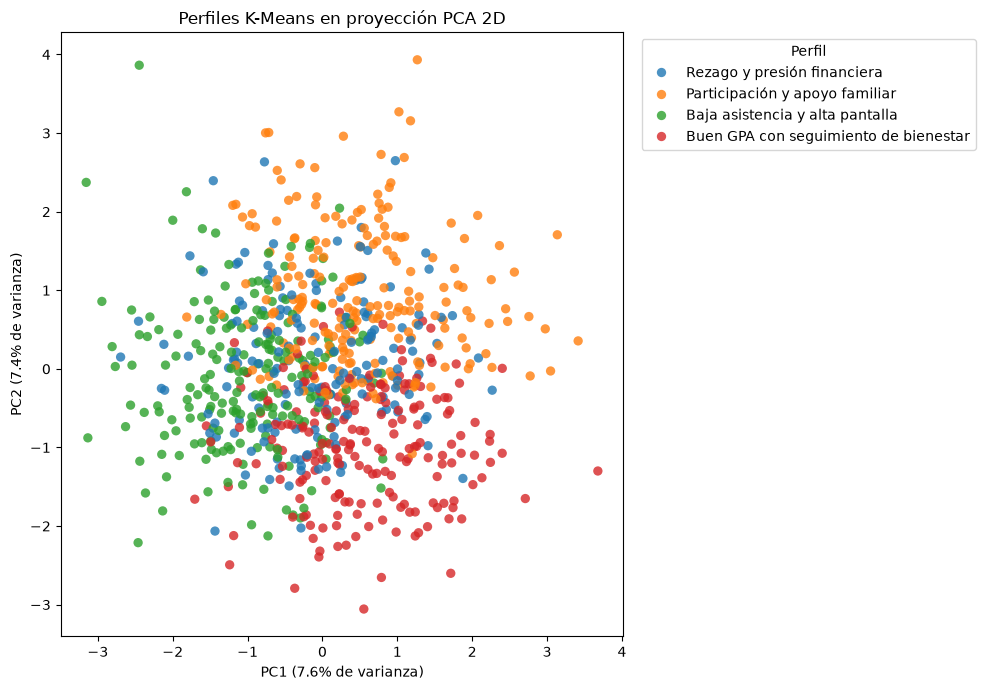

In [8]:
# La proyección se carga del artefacto fundacional para asegurar el mismo PCA y el mismo orden de filas.
pca_2d = pd.read_csv(DATA / "pca_2d.csv")
# Esta condición detiene la celda si las tres fuentes no tienen una fila por estudiante en el mismo orden.
if len(pca_2d) != len(labels_kmeans) or len(df) != len(labels_kmeans):
    raise ValueError("Las filas de PCA, etiquetas y CSV original deben estar alineadas.")
# Se agregan nombres descriptivos a las etiquetas existentes; las asignaciones no se recalculan en 2D.
plot_data = pca_2d.copy()
plot_data["segmento"] = pd.Series(labels_kmeans).map({k: v["name"] for k, v in segment_descriptions.items()}).values

# Cada punto representa un estudiante; el color identifica el segmento aprendido en 16D.
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="segmento", hue_order=[v["name"] for v in segment_descriptions.values()],
                palette="tab10", s=45, alpha=.8, edgecolor="none", ax=ax)
ax.set_title("Perfiles K-Means en proyección PCA 2D")
ax.set_xlabel(f"PC1 ({pca_variance.loc[0, 'explained_variance']:.1%} de varianza)")
ax.set_ylabel(f"PC2 ({pca_variance.loc[1, 'explained_variance']:.1%} de varianza)")
ax.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación y Argumento para Defensa:** el gráfico muestra los 800 registros coloreados con las etiquetas aprendidas en 16D. PC1 y PC2 explican juntas 15,04 % de la varianza; una apariencia de solapamiento en 2D no invalida ni confirma por sí sola el agrupamiento original. **Decisión técnica:** se usa la proyección como apoyo visual, sin recalcular etiquetas en PCA. **Defensa:** las asignaciones se obtuvieron en 16D y luego se proyectaron para visualizar; PCA no fue el espacio de entrenamiento.

## Fase 7 — Exportación de artefactos del Paquete A

**Propósito y fundamento:** se serializa el Pipeline entrenado para que futuras predicciones repitan imputación, escalado y asignación de cluster. También se guardan etiquetas en orden original, medias en escala original, proporciones descriptivas, nombres de perfiles, métricas y gráficos. Las etiquetas de clase no participan en ninguna salida de entrenamiento. Las tablas se ajustan a los nombres y columnas del contrato técnico.

In [9]:
# json guarda el diccionario legible y joblib serializa el Pipeline de sklearn.
import json
import joblib

# Se crean los directorios de salida si aún no existen, sin modificar otros datos del proyecto.
for folder in [ROOT / "models", ROOT / "segments", ROOT / "tables", ROOT / "figs"]:
    folder.mkdir(parents=True, exist_ok=True)

# Pipeline sklearn para inferencia directa desde variables crudas.
# El artefacto conserva imputador, escalador y K-Means ya entrenados para inferencia posterior.
joblib.dump(pipeline_kmeans, ROOT / "models" / "pipeline_kmeans.joblib")

# Perfiles: solo cluster, n, las 16 medias originales y las dos proporciones requeridas.
# El orden explícito asegura que el CSV cumpla exactamente el esquema de la guía.
profile_columns = ["cluster", "n", *FEATURES, "prop_part_time_job", "prop_counseling_access"]
profile_export = profiles_kmeans.loc[:, profile_columns].copy()
profile_export.to_csv(ROOT / "segments" / "perfiles_kmeans.csv", index=False)

# Una etiqueta por fila, conservando el orden del CSV original.
# Se escribe una sola columna, alineada por posición con las filas del archivo original.
pd.DataFrame({"cluster": labels_kmeans}).to_csv(ROOT / "segments" / "labels_kmeans.csv", index=False)

# JSON requiere las etiquetas como claves de texto.
# Las claves JSON se convierten a texto porque el formato no admite claves enteras.
segment_names = {str(int(k)): value["name"] for k, value in segment_descriptions.items()}
(ROOT / "segments" / "segments_kmeans.json").write_text(
    json.dumps(segment_names, ensure_ascii=False, indent=2), encoding="utf-8"
)

# Metría calculada sobre el ajuste final en 16D.
# Las métricas se calculan desde el ajuste final, no se copian de valores escritos a mano.
final_inertia = float(pipeline_kmeans.named_steps["kmeans"].inertia_)
final_silhouette = float(silhouette_score(X_model_space, labels_kmeans))
# K-Means no tiene ruido ni parámetros eps/min_samples; estos campos se registran como 0 y NaN.
metrics_columns = ["model", "n_clusters", "silhouette", "noise_pct", "inertia", "eps", "min_samples"]
metrics_kmeans = pd.DataFrame([{
    "model": "kmeans",
    "n_clusters": int(selected_k),
    "silhouette": final_silhouette,
    "noise_pct": 0.0,
    "inertia": final_inertia,
    "eps": np.nan,
    "min_samples": np.nan,
}], columns=metrics_columns)
metrics_kmeans.to_csv(ROOT / "tables" / "metrics_kmeans.csv", index=False)

# Figuras de selección de K.
# Las figuras se vuelven a guardar como PNG independientes para el informe y la entrega.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["inertia"], marker="o", color="#2c7bb6")
ax.axvline(selected_k, color="#d7191c", linestyle="--", label=f"K seleccionado = {selected_k}")
ax.set(title="Método del codo", xlabel="Número de clusters K", ylabel="Inercia")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "figs" / "codo_kmeans.png", dpi=180, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection["K"], selection["silhouette"], marker="o", color="#1a9641")
ax.axvline(selected_k, color="#d7191c", linestyle="--", label=f"K seleccionado = {selected_k}")
ax.set(title="Silhouette sobre 16 dimensiones", xlabel="Número de clusters K", ylabel="Coeficiente Silhouette")
ax.set_xticks(selection["K"])
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "figs" / "silhouette_kmeans.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# El mapa exportado reutiliza PCA 2D y las etiquetas ya aprendidas en el espacio de 16 variables.
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="segmento",
                hue_order=[v["name"] for v in segment_descriptions.values()], palette="tab10",
                s=45, alpha=.8, edgecolor="none", ax=ax)
ax.set_title("Perfiles K-Means en proyección PCA 2D")
ax.set_xlabel(f"PC1 ({pca_variance.loc[0, 'explained_variance']:.1%} de varianza)")
ax.set_ylabel(f"PC2 ({pca_variance.loc[1, 'explained_variance']:.1%} de varianza)")
ax.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(ROOT / "figs" / "pca_kmeans.png", dpi=180, bbox_inches="tight")
plt.close(fig)

print("Artefactos escritos:")
for artifact in [
    "models/pipeline_kmeans.joblib",
    "segments/perfiles_kmeans.csv",
    "segments/labels_kmeans.csv",
    "segments/segments_kmeans.json",
    "tables/metrics_kmeans.csv",
    "figs/codo_kmeans.png",
    "figs/silhouette_kmeans.png",
    "figs/pca_kmeans.png",
]:
    print("-", artifact)
print("Métricas finales:")
display(metrics_kmeans.round(4))
print("Perfiles exportados:", profile_export.shape)
print("Etiquetas exportadas:", len(labels_kmeans), "en orden original")

Artefactos escritos:
- models/pipeline_kmeans.joblib
- segments/perfiles_kmeans.csv
- segments/labels_kmeans.csv
- segments/segments_kmeans.json
- tables/metrics_kmeans.csv
- figs/codo_kmeans.png
- figs/silhouette_kmeans.png
- figs/pca_kmeans.png
Métricas finales:


,model,n_clusters,silhouette,noise_pct,inertia,eps,min_samples
0,kmeans,4,0.0475,0.0,11290.7045,NaN,NaN


Perfiles exportados: (4, 20)
Etiquetas exportadas: 800 en orden original


**Interpretación y Argumento para Defensa:** el Pipeline, las métricas, los perfiles, las etiquetas ordenadas, el diccionario descriptivo y las figuras quedan guardados en sus rutas acordadas. El CSV de etiquetas conserva 800 filas alineadas con el original; el Pipeline recibe variables crudas. **Decisión técnica:** `Student_ID` y las etiquetas objetivo quedan excluidos; empleo y consejería solo aparecen como proporciones descriptivas. **Defensa:** los segmentos se descubren con las 16 variables numéricas y sus nombres/recomendaciones se asignan después de inspeccionar los perfiles.